# MediaPipe Gesture Recognition — Video Call RTP Stream Test

Notebook này thực hiện:
1. **Parse file pcap** (`video/input_video.txt`) — trích xuất RTP H264 packets (giống logic của `mock-video-rtp-sender`)
2. **Reassemble H264 NALUs** từ RTP (xử lý NAL type 1/single, 24/STAP-A, 28/FU-A, 7/SPS, 8/PPS)
3. **Decode H264 → video frames** bằng PyAV (ffmpeg bindings)
4. **Feed frames vào MediaPipe GestureRecognizer** ở mode `LIVE_STREAM` với timestamp pacing thực tế
5. **Hiển thị kết quả** nhận diện cử chỉ tay — sẵn sàng tích hợp video call real-time

## 1. Cài đặt dependencies

In [1]:
# Cài đặt Python packages và thư viện hệ thống cần thiết (libgles2 cho MediaPipe C-bindings)
%pip install mediapipe av matplotlib opencv-python --quiet
!which dpkg >/dev/null 2>&1 && (dpkg -l | grep -q libgles2 || (sudo apt-get update -qq && sudo apt-get install -y -qq libgles2))


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
MODEL_PATH = 'gesture_recognizer.task'
if not os.path.exists(MODEL_PATH):
    !wget -q https://storage.googleapis.com/mediapipe-models/gesture_recognizer/gesture_recognizer/float16/latest/gesture_recognizer.task
    print('Downloaded gesture_recognizer.task')
else:
    print(f'Model already exists: {MODEL_PATH} ({os.path.getsize(MODEL_PATH)} bytes)')

Model already exists: gesture_recognizer.task (8373440 bytes)


## 2. Parse PCAP — Trích xuất RTP H264 packets

Logic tương đương `pcap.go` trong `mock-video-rtp-sender`:
- Đọc pcap global header và từng packet
- Parse Ethernet → VLAN (0x8100) → IPv4 → UDP → RTP
- Lọc RTP packets (version=2, không phải RTCP)
- Nhóm theo SSRC, phát hiện SPS/PPS để xác định H264 stream hợp lệ

In [3]:
import struct
from dataclasses import dataclass, field
from typing import Optional


@dataclass
class RTPPacket:
    """Parsed RTP packet from pcap capture."""
    version: int
    padding: bool
    extension: bool
    cc: int
    marker: bool
    payload_type: int
    sequence_number: int
    timestamp: int
    ssrc: int
    payload: bytes
    capture_time: float  # seconds since pcap start


@dataclass
class CaptureStream:
    """H264 RTP stream detected in pcap (mirrors captureStream in pcap.go)."""
    index: int = 0
    ssrc: int = 0
    payload_type: int = 0
    packets: list = field(default_factory=list)
    frames: int = 0
    has_sps: bool = False
    has_pps: bool = False
    first_capture_ts: float = 0.0

    @property
    def is_valid_h264(self) -> bool:
        return self.has_sps and self.has_pps and self.frames > 0

    @property
    def duration(self) -> float:
        if not self.packets:
            return 0.0
        return self.packets[-1].capture_time - self.packets[0].capture_time


def _note_parameter_sets(stream: CaptureStream, payload: bytes):
    """Detect SPS/PPS in RTP payload (mirrors noteParameterSets in pcap.go)."""
    if not payload:
        return
    nal_type = payload[0] & 0x1f
    if nal_type == 7:  # SPS
        stream.has_sps = True
    elif nal_type == 8:  # PPS
        stream.has_pps = True
    elif nal_type == 24:  # STAP-A: aggregated NALs
        idx = 1
        while idx + 2 <= len(payload):
            size = struct.unpack('>H', payload[idx:idx+2])[0]
            idx += 2
            if size == 0 or idx + size > len(payload):
                break
            inner_nal = payload[idx] & 0x1f
            if inner_nal == 7:
                stream.has_sps = True
            elif inner_nal == 8:
                stream.has_pps = True
            idx += size


def parse_rtp_from_raw(rtp_data: bytes, capture_time: float) -> Optional[RTPPacket]:
    """Parse raw RTP bytes into an RTPPacket."""
    if len(rtp_data) < 12:
        return None
    # RTCP filter (PT 192..223)
    if 192 <= rtp_data[1] <= 223:
        return None

    version = (rtp_data[0] >> 6) & 3
    if version != 2:
        return None

    padding = bool((rtp_data[0] >> 5) & 1)
    extension = bool((rtp_data[0] >> 4) & 1)
    cc = rtp_data[0] & 0x0f
    marker = bool((rtp_data[1] >> 7) & 1)
    pt = rtp_data[1] & 0x7f
    seq = struct.unpack('>H', rtp_data[2:4])[0]
    ts = struct.unpack('>I', rtp_data[4:8])[0]
    ssrc = struct.unpack('>I', rtp_data[8:12])[0]

    offset = 12 + cc * 4
    if extension and len(rtp_data) > offset + 4:
        ext_len = struct.unpack('>H', rtp_data[offset+2:offset+4])[0]
        offset += 4 + ext_len * 4

    payload = rtp_data[offset:]
    if padding and len(payload) > 0:
        pad_len = payload[-1]
        payload = payload[:-pad_len] if pad_len < len(payload) else b''

    if len(payload) == 0:
        return None

    return RTPPacket(
        version=version, padding=padding, extension=extension, cc=cc,
        marker=marker, payload_type=pt, sequence_number=seq,
        timestamp=ts, ssrc=ssrc, payload=payload, capture_time=capture_time,
    )


def read_pcap(path: str) -> list[CaptureStream]:
    """
    Read pcap file and extract H264 RTP streams.
    Mirrors readCapture() in mock-video-rtp-sender/pcap.go.
    Supports Ethernet + VLAN (0x8100) + IPv4 + UDP.
    """
    streams_by_flow: dict[str, CaptureStream] = {}
    all_streams: list[CaptureStream] = []

    with open(path, 'rb') as f:
        # Global header
        magic = struct.unpack('<I', f.read(4))[0]
        assert magic == 0xa1b2c3d4, f'Unsupported pcap magic: 0x{magic:08x}'
        _ver_major, _ver_minor, _thiszone, _sigfigs, _snaplen, network = \
            struct.unpack('<HHIIII', f.read(20))

        first_global_ts = None

        while True:
            header = f.read(16)
            if len(header) < 16:
                break
            ts_sec, ts_usec, incl_len, orig_len = struct.unpack('<IIII', header)
            data = f.read(incl_len)
            if len(data) < incl_len:
                break

            cap_ts = ts_sec + ts_usec / 1_000_000
            if first_global_ts is None:
                first_global_ts = cap_ts

            # Ethernet (link type 1)
            if network != 1 or len(data) < 14:
                continue

            offset = 12
            eth_type = struct.unpack('>H', data[offset:offset+2])[0]
            offset += 2

            # Skip VLAN tags (802.1Q)
            while eth_type == 0x8100 and offset + 4 <= len(data):
                offset += 2  # skip TCI
                eth_type = struct.unpack('>H', data[offset:offset+2])[0]
                offset += 2

            if eth_type != 0x0800:  # Not IPv4
                continue

            ip_start = offset
            if ip_start + 20 > len(data):
                continue
            ihl = (data[ip_start] & 0xf) * 4
            proto = data[ip_start + 9]
            if proto != 17:  # Not UDP
                continue

            udp_start = ip_start + ihl
            if udp_start + 8 > len(data):
                continue

            rtp_data = data[udp_start + 8:]
            pkt = parse_rtp_from_raw(rtp_data, cap_ts - first_global_ts)
            if pkt is None:
                continue

            flow_key = f'{pkt.ssrc}/{pkt.payload_type}'
            if flow_key not in streams_by_flow:
                stream = CaptureStream(
                    ssrc=pkt.ssrc,
                    payload_type=pkt.payload_type,
                    first_capture_ts=cap_ts - first_global_ts,
                )
                streams_by_flow[flow_key] = stream
                all_streams.append(stream)

            stream = streams_by_flow[flow_key]
            _note_parameter_sets(stream, pkt.payload)
            stream.packets.append(pkt)
            if pkt.marker:
                stream.frames += 1

    # Filter to valid H264 streams only (like pcap.go)
    h264_streams = [s for s in all_streams if s.is_valid_h264]
    for i, s in enumerate(h264_streams):
        s.index = i

    return h264_streams


# Parse the pcap
PCAP_PATH = 'video/input_video.txt'
streams = read_pcap(PCAP_PATH)

print(f'Found {len(streams)} H264 stream(s) in pcap:')
for s in streams:
    print(f'  Stream {s.index}: SSRC={s.ssrc}, PT={s.payload_type}, '
          f'{len(s.packets)} packets, {s.frames} frames, '
          f'duration={s.duration:.1f}s, ~{s.frames/max(s.duration, 0.001):.1f} fps')

Found 2 H264 stream(s) in pcap:
  Stream 0: SSRC=783744673, PT=114, 637 packets, 616 frames, duration=41.0s, ~15.0 fps
  Stream 1: SSRC=1556918416, PT=114, 1741 packets, 594 frames, duration=39.9s, ~14.9 fps


## 3. Reassemble H264 NALUs từ RTP packets

Xử lý các NAL unit type theo RFC 6184:
- **Type 1-23 (Single NAL):** Payload chính là 1 NAL unit
- **Type 24 (STAP-A):** Aggregated — chứa nhiều NAL units nhỏ (thường SPS+PPS)
- **Type 28 (FU-A):** Fragmented — 1 NAL unit lớn được chia thành nhiều RTP packets

Kết quả: danh sách Access Units, mỗi AU gồm các NAL bytes ở dạng Annex-B (start code `00 00 00 01`)

In [4]:
@dataclass
class AccessUnit:
    """One video frame's worth of H264 NALUs with timing info."""
    nalus: list[bytes] = field(default_factory=list)
    rtp_timestamp: int = 0
    capture_time: float = 0.0  # seconds from pcap start


ANNEX_B_START_CODE = b'\x00\x00\x00\x01'


def reassemble_h264_access_units(
    packets: list[RTPPacket],
    max_duration: float = None,
) -> list[AccessUnit]:
    """
    Reassemble RTP packets into H264 Access Units.
    Mirrors the frame grouping logic in mock-video-rtp-sender.
    
    Each Access Unit corresponds to one video frame, grouped by RTP timestamp.
    The marker bit indicates the last packet of an Access Unit.
    """
    access_units: list[AccessUnit] = []
    current_au = AccessUnit()
    fu_a_buffer = bytearray()  # For FU-A fragment reassembly
    
    start_time = packets[0].capture_time if packets else 0.0

    for pkt in packets:
        if max_duration and (pkt.capture_time - start_time) > max_duration:
            break

        # New RTP timestamp → new Access Unit
        if current_au.nalus and pkt.timestamp != current_au.rtp_timestamp:
            if fu_a_buffer:
                current_au.nalus.append(bytes(fu_a_buffer))
                fu_a_buffer.clear()
            access_units.append(current_au)
            current_au = AccessUnit()

        current_au.rtp_timestamp = pkt.timestamp
        current_au.capture_time = pkt.capture_time

        payload = pkt.payload
        nal_type = payload[0] & 0x1f

        if 1 <= nal_type <= 23:
            # Single NAL unit — payload IS the NAL
            if fu_a_buffer:
                current_au.nalus.append(bytes(fu_a_buffer))
                fu_a_buffer.clear()
            current_au.nalus.append(bytes(payload))

        elif nal_type == 24:  # STAP-A
            if fu_a_buffer:
                current_au.nalus.append(bytes(fu_a_buffer))
                fu_a_buffer.clear()
            idx = 1
            while idx + 2 <= len(payload):
                size = struct.unpack('>H', payload[idx:idx+2])[0]
                idx += 2
                if size == 0 or idx + size > len(payload):
                    break
                current_au.nalus.append(bytes(payload[idx:idx+size]))
                idx += size

        elif nal_type == 28:  # FU-A
            fu_indicator = payload[0]
            fu_header = payload[1]
            start_bit = (fu_header >> 7) & 1
            end_bit = (fu_header >> 6) & 1
            fu_nal_type = fu_header & 0x1f

            if start_bit:
                # First fragment — reconstruct NAL header
                if fu_a_buffer:
                    current_au.nalus.append(bytes(fu_a_buffer))
                fu_a_buffer = bytearray()
                reconstructed_header = (fu_indicator & 0xe0) | fu_nal_type
                fu_a_buffer.append(reconstructed_header)
                fu_a_buffer.extend(payload[2:])
            else:
                # Continuation or end fragment
                fu_a_buffer.extend(payload[2:])

            if end_bit:
                current_au.nalus.append(bytes(fu_a_buffer))
                fu_a_buffer.clear()

        # Marker bit → end of Access Unit
        if pkt.marker:
            if fu_a_buffer:
                current_au.nalus.append(bytes(fu_a_buffer))
                fu_a_buffer.clear()
            if current_au.nalus:
                access_units.append(current_au)
                current_au = AccessUnit()

    # Don't include incomplete final AU
    return access_units


def access_units_to_annex_b(aus: list[AccessUnit]) -> bytes:
    """Convert Access Units to Annex-B byte stream for decoder."""
    parts = []
    for au in aus:
        for nalu in au.nalus:
            parts.append(ANNEX_B_START_CODE)
            parts.append(nalu)
    return b''.join(parts)


# ─── Lựa chọn Stream để xử lý ───
# File PCAP chứa 2 luồng video H.264:
#   • Stream 0 (SSRC 783744673): Góc camera quay trần nhà/phông nền (không có người)
#   • Stream 1 (SSRC 1556918416): Camera góc người gọi video call (có bàn tay & cử chỉ)
STREAM_INDEX = 1  # Mặc định chọn Stream 1 để nhận diện cử chỉ người gọi video call
selected_stream = streams[STREAM_INDEX]
print(f'Selected stream {STREAM_INDEX}: SSRC={selected_stream.ssrc}')

# Reassemble Access Units
access_units = reassemble_h264_access_units(selected_stream.packets)

print(f'Reassembled {len(access_units)} Access Units (frames)')
print(f'First 5 AUs:')
for i, au in enumerate(access_units[:5]):
    nal_types = [n[0] & 0x1f for n in au.nalus if n]
    total_size = sum(len(n) for n in au.nalus)
    print(f'  AU {i}: ts={au.rtp_timestamp}, time={au.capture_time:.3f}s, '
          f'{len(au.nalus)} NALUs, types={nal_types}, size={total_size} bytes')

Selected stream 1: SSRC=1556918416
Reassembled 594 Access Units (frames)
First 5 AUs:
  AU 0: ts=71830385, time=0.960s, 3 NALUs, types=[7, 8, 5], size=3458 bytes
  AU 1: ts=71842371, time=1.030s, 1 NALUs, types=[1], size=2204 bytes
  AU 2: ts=71848365, time=1.115s, 1 NALUs, types=[1], size=937 bytes
  AU 3: ts=71854522, time=1.195s, 1 NALUs, types=[1], size=2345 bytes
  AU 4: ts=71860680, time=1.215s, 1 NALUs, types=[1], size=2380 bytes


## 4. Decode H264 → Video Frames

Sử dụng PyAV (ffmpeg bindings) để decode Annex-B H264 bitstream thành RGB frames.
Mỗi frame sẽ được gắn kèm timestamp (capture_time) từ pcap để phục vụ LIVE_STREAM mode.

In [5]:
import av
import numpy as np
from dataclasses import dataclass


@dataclass
class DecodedFrame:
    """A decoded video frame with timing information."""
    image: np.ndarray        # RGB uint8 HxWx3
    rtp_timestamp: int       # Original RTP timestamp
    capture_time: float      # Seconds from pcap start
    frame_index: int         # Sequential frame number


def decode_h264_frames(access_units_list: list[AccessUnit]) -> list[DecodedFrame]:
    """
    Decode H264 Access Units to RGB frames using PyAV.
    Preserves timing information from pcap for LIVE_STREAM pacing.
    """
    # Build Annex-B byte stream
    h264_bytes = access_units_to_annex_b(access_units_list)
    print(f'H264 bitstream: {len(h264_bytes)} bytes')

    # Decode using PyAV
    codec = av.CodecContext.create('h264', 'r')
    codec.open()

    decoded_frames: list[DecodedFrame] = []
    
    # Feed all data and decode
    packets_av = codec.parse(h264_bytes)
    au_index = 0
    
    for pkt_av in packets_av:
        try:
            frames = codec.decode(pkt_av)
            for frame in frames:
                rgb_frame = frame.to_ndarray(format='rgb24')
                
                # Map decoded frame to original AU timing
                if au_index < len(access_units_list):
                    au = access_units_list[au_index]
                    rtp_ts = au.rtp_timestamp
                    cap_time = au.capture_time
                else:
                    rtp_ts = 0
                    cap_time = 0.0

                decoded_frames.append(DecodedFrame(
                    image=rgb_frame,
                    rtp_timestamp=rtp_ts,
                    capture_time=cap_time,
                    frame_index=len(decoded_frames),
                ))
                au_index += 1
        except av.error.InvalidDataError:
            continue

    # Flush remaining frames
    try:
        for frame in codec.decode(None):
            rgb_frame = frame.to_ndarray(format='rgb24')
            if au_index < len(access_units_list):
                au = access_units_list[au_index]
                rtp_ts = au.rtp_timestamp
                cap_time = au.capture_time
            else:
                rtp_ts = 0
                cap_time = 0.0
            decoded_frames.append(DecodedFrame(
                image=rgb_frame,
                rtp_timestamp=rtp_ts,
                capture_time=cap_time,
                frame_index=len(decoded_frames),
            ))
            au_index += 1
    except av.error.InvalidDataError:
        pass

    del codec  # PyAV codec contexts are released via garbage collection
    return decoded_frames


# Decode all frames
decoded_frames = decode_h264_frames(access_units)

print(f'\nDecoded {len(decoded_frames)} frames')
if decoded_frames:
    f0 = decoded_frames[0]
    print(f'Frame size: {f0.image.shape[1]}x{f0.image.shape[0]} (WxH)')
    print(f'Duration: {decoded_frames[-1].capture_time:.1f}s')
    fps_est = len(decoded_frames) / max(decoded_frames[-1].capture_time, 0.001)
    print(f'Estimated FPS: {fps_est:.1f}')

H264 bitstream: 1586495 bytes

Decoded 593 frames
Frame size: 240x320 (WxH)
Duration: 40.8s
Estimated FPS: 14.5


## 5. Preview — Xem trước một số frame đã decode

In [6]:
# import matplotlib.pyplot as plt

# if decoded_frames:
#     # Show 8 evenly-spaced sample frames
#     n_samples = min(8, len(decoded_frames))
#     indices = [int(i * (len(decoded_frames) - 1) / (n_samples - 1)) for i in range(n_samples)]
    
#     fig, axes = plt.subplots(2, 4, figsize=(16, 6))
#     for ax, idx in zip(axes.flat, indices):
#         f = decoded_frames[idx]
#         ax.imshow(f.image)
#         ax.set_title(f'Frame {idx} | t={f.capture_time:.2f}s', fontsize=9)
#         ax.axis('off')
#     plt.suptitle('Decoded frames from pcap H264 RTP stream', fontsize=12)
#     plt.tight_layout()
#     plt.show()
# else:
#     print('No frames decoded!')

## 6. MediaPipe Gesture Recognition — LIVE_STREAM mode

### Mô phỏng luồng video call real-time:
- Sử dụng `RunningMode.LIVE_STREAM` — chế độ async, gọi callback khi có kết quả
- Feed frame theo thứ tự thời gian với **monotonic increasing timestamp** (yêu cầu của MediaPipe)
- Pacing theo `capture_time` từ pcap (giống mock-video-rtp-sender `time.Sleep` logic)
- Callback thu thập kết quả gesture recognition để phân tích sau

### Tích hợp video call:
Trong hệ thống thực, thay vì đọc pcap, bạn sẽ:
1. Nhận RTP packets từ UDP socket (port 41000 từ mock hoặc WebRTC)
2. Reassemble H264 → Decode → Feed MediaPipe
3. Sử dụng kết quả gesture để trigger actions (mute, react, etc.)

In [7]:
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
import time
import threading
import cv2
import numpy as np
from collections import defaultdict, deque
from IPython.display import display, Image, clear_output
from dataclasses import dataclass

# Load emojis
EMOJI_MAP = {
    'Closed_Fist': 'emojis/270a.png',
    'Open_Palm': 'emojis/1f590.png',
    'Pointing_Up': 'emojis/261d.png',
    'Thumb_Down': 'emojis/1f44e.png',
    'Thumb_Up': 'emojis/1f44d.png',
    'Victory': 'emojis/270c.png',
    'ILoveYou': 'emojis/1f91f.png',
    'Wave': 'emojis/1f590.png',   # You can use a different icon for wave
    'Clap': 'emojis/1f44d.png'    # Or different icon for clap
}
loaded_emojis = {}
for g, path in EMOJI_MAP.items():
    import os
    if os.path.exists(path):
        emoji_bgra = cv2.imread(path, cv2.IMREAD_UNCHANGED)
        if emoji_bgra is not None:
            emoji_rgba = cv2.cvtColor(emoji_bgra, cv2.COLOR_BGRA2RGBA)
            emoji_rgba = cv2.resize(emoji_rgba, (50, 50))
            loaded_emojis[g] = emoji_rgba

def overlay_image_alpha(img, img_overlay, x, y, alpha_mask):
    y1, y2 = max(0, y), min(img.shape[0], y + img_overlay.shape[0])
    x1, x2 = max(0, x), min(img.shape[1], x + img_overlay.shape[1])
    y1o, y2o = max(0, -y), min(img_overlay.shape[0], img.shape[0] - y)
    x1o, x2o = max(0, -x), min(img_overlay.shape[1], img.shape[1] - x)
    if y1 >= y2 or x1 >= x2 or y1o >= y2o or x1o >= x2o:
        return
    img_crop = img[y1:y2, x1:x2]
    img_overlay_crop = img_overlay[y1o:y2o, x1o:x2o]
    alpha = alpha_mask[y1o:y2o, x1o:x2o, np.newaxis]
    img_crop[:] = alpha * img_overlay_crop + (1 - alpha) * img_crop

DEVICE = 'CPU'

def get_base_options(model_path: str, device: str = 'CPU') -> mp.tasks.BaseOptions:
    device_upper = device.strip().upper()
    if device_upper == 'GPU':
        delegate = mp.tasks.BaseOptions.Delegate.GPU
        print('⚡ Đã cấu hình Delegate: GPU')
    else:
        delegate = mp.tasks.BaseOptions.Delegate.CPU
        print('💻 Đã cấu hình Delegate: CPU (XNNPACK)')
    return mp.tasks.BaseOptions(model_asset_path=model_path, delegate=delegate)


# --- THUẬT TOÁN NHẬN DIỆN DYNAMIC GESTURE (RULE-BASED) ---
class DynamicGestureRecognizer:
    def __init__(self, window_size=20, wave_threshold=3):
        self.window_size = window_size
        self.history = deque(maxlen=window_size)
        self.gesture_cooldown = 0
        self.last_dynamic_gesture = None
        self.wave_threshold = wave_threshold
        
    def update(self, hand_landmarks_list, timestamp_ms):
        if self.gesture_cooldown > 0:
            self.gesture_cooldown -= 1
            if self.gesture_cooldown == 0:
                self.last_dynamic_gesture = None
                
        self.history.append({'timestamp': timestamp_ms, 'hands': hand_landmarks_list})
        
        # Nếu đang cooldown thì giữ nguyên gesture trước đó
        if self.gesture_cooldown > 0:
            return self.last_dynamic_gesture
            
        # Phân tích heuristics
        gesture = self.detect_wave()
        if gesture:
            self.last_dynamic_gesture = gesture
            self.gesture_cooldown = 15  # Đóng băng kết quả trong 15 frames để chống nhiễu
            return gesture
            
        gesture = self.detect_clap()
        if gesture:
            self.last_dynamic_gesture = gesture
            self.gesture_cooldown = 15
            return gesture
            
        return None
        
    def detect_wave(self):
        if len(self.history) < 10:
            return None
            
        # Trích xuất tọa độ X của cổ tay (wrist) cho bàn tay đầu tiên
        wrist_x_history = []
        for frame in self.history:
            if frame['hands'] and len(frame['hands']) > 0:
                wrist_x_history.append(frame['hands'][0][0].x)
                
        if len(wrist_x_history) < 10:
            return None
            
        # Đếm số lần đổi hướng di chuyển (vẫy qua lại)
        direction_changes = 0
        last_diff = 0
        for i in range(1, len(wrist_x_history)):
            diff = wrist_x_history[i] - wrist_x_history[i-1]
            if diff * last_diff < 0 and abs(diff) > 0.01:
                direction_changes += 1
            if abs(diff) > 0.01:
                last_diff = diff
                
        amplitude = max(wrist_x_history) - min(wrist_x_history)
        
        if direction_changes >= self.wave_threshold and amplitude > 0.05:
            return "Wave"
            
        return None
        
    def detect_clap(self):
        if len(self.history) < 5:
            return None
            
        distances = []
        for frame in self.history:
            if frame['hands'] and len(frame['hands']) == 2:
                w1 = frame['hands'][0][0]
                w2 = frame['hands'][1][0]
                dist = np.sqrt((w1.x - w2.x)**2 + (w1.y - w2.y)**2)
                distances.append(dist)
                
        if len(distances) < 5:
            return None
            
        # Vỗ tay: khoảng cách giảm mạnh và rất nhỏ
        if distances[-1] < 0.1 and distances[0] > 0.2:
            return "Clap"
            
        return None

# Global dynamic recognizer
dynamic_recognizer = DynamicGestureRecognizer()


@dataclass
class GestureResult:
    timestamp_ms: int
    gestures: list
    handedness: list
    hand_landmarks_count: int
    processing_time_ms: float = 0.0

gesture_results: list[GestureResult] = []
results_lock = threading.Lock()
gesture_counts = defaultdict(int)
callback_times: list[float] = []

latest_hand_results_for_overlay = []
latest_dynamic_gesture = None

def gesture_result_callback(result: mp_vision.GestureRecognizerResult, output_image: mp.Image, timestamp_ms: int):
    global latest_hand_results_for_overlay, latest_dynamic_gesture
    cb_time = time.monotonic()
    
    # 1. Update Dynamic Gesture Recognizer
    start_dynamic_time = time.perf_counter()
    detected_dynamic = dynamic_recognizer.update(result.hand_landmarks, timestamp_ms)
    dynamic_processing_time = (time.perf_counter() - start_dynamic_time) * 1000
    
    if detected_dynamic:
        latest_dynamic_gesture = detected_dynamic
    else:
        latest_dynamic_gesture = None

    hand_results = []
    gestures = []
    handedness_list = []
    landmarks_count = 0

    if result.hand_landmarks:
        landmarks_count = sum(len(lm) for lm in result.hand_landmarks)

    if result.handedness:
        for hand in result.handedness:
            for h in hand:
                handedness_list.append((h.category_name, h.score))

    if result.hand_landmarks and result.gestures:
        for hand_landmarks, hand_gestures in zip(result.hand_landmarks, result.gestures):
            best_gesture = hand_gestures[0] if hand_gestures else None
            
            # Ghi đè Static Gesture bằng Dynamic Gesture nếu có
            if latest_dynamic_gesture:
                g_name = latest_dynamic_gesture
                g_score = 1.0
            elif best_gesture:
                g_name = best_gesture.category_name
                g_score = best_gesture.score
            else:
                g_name = 'None'
                g_score = 0.0
                
            if g_name != 'None':
                gestures.append((g_name, g_score))
                gesture_counts[g_name] += 1
                hand_results.append({
                    'gesture': g_name,
                    'score': g_score,
                    'landmarks': hand_landmarks
                })
    
    latest_hand_results_for_overlay = hand_results

    gr = GestureResult(
        timestamp_ms=timestamp_ms,
        gestures=gestures,
        handedness=handedness_list,
        hand_landmarks_count=landmarks_count,
    )

    with results_lock:
        callback_times.append(cb_time)
        gesture_results.append(gr)

def draw_gesture_overlay(img_rgb, hand_results, frame_info=""):
    canvas = img_rgb.copy()
    h, w = canvas.shape[:2]
    cv2.rectangle(canvas, (0, 0), (w, 32), (20, 20, 20), -1)

    text_parts = []
    
    for hand_res in hand_results:
        g_name = hand_res['gesture']
        g_score = hand_res['score']
        lms = hand_res['landmarks']
        
        if g_name != 'None':
            text_parts.append(f'{g_name} ({g_score:.2f})')
            if g_name in loaded_emojis and lms:
                cx = int(lms[0].x * w)
                cy = int(lms[0].y * h)
                emoji_rgba = loaded_emojis[g_name]
                icon_h, icon_w = emoji_rgba.shape[:2]
                icon_rgb = emoji_rgba[:, :, :3]
                icon_alpha = emoji_rgba[:, :, 3] / 255.0
                overlay_image_alpha(canvas, icon_rgb, cx - icon_w//2, cy - icon_h - 20, icon_alpha)
        
        if lms:
            for lm in lms:
                cx, cy = int(lm.x * w), int(lm.y * h)
                cv2.circle(canvas, (cx, cy), 3, (0, 255, 255), -1)

    if text_parts:
        text = "🤚 " + " | ".join(text_parts)
        color = (0, 255, 120)
    else:
        text = 'No Hand / None'
        color = (130, 130, 130)

    cv2.putText(canvas, text, (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    if frame_info:
        cv2.putText(canvas, frame_info, (w - 110, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (220, 220, 220), 1)

    return canvas

print(f'Gesture recognition callback & visualizer configured. Thiết bị: {DEVICE}')


Gesture recognition callback & visualizer configured. Thiết bị: CPU


In [8]:
import time
import os
import cv2

os.makedirs('runs', exist_ok=True)

VISUALIZE_REALTIME = True  
DISPLAY_EVERY_N_FRAMES = 2  
SAVE_OUTPUT_PCAP = True  # Option lưu output video cho luồng PCAP

BaseOptions = mp.tasks.BaseOptions
GestureRecognizer = mp.tasks.vision.GestureRecognizer
GestureRecognizerOptions = mp.tasks.vision.GestureRecognizerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

active_device = DEVICE
print(f'Khởi tạo GestureRecognizer với cấu hình: DEVICE={active_device}...')

try:
    base_options = get_base_options(MODEL_PATH, device=active_device)
    options = GestureRecognizerOptions(
        base_options=base_options,
        running_mode=VisionRunningMode.LIVE_STREAM,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5,
        result_callback=gesture_result_callback,
    )
    with GestureRecognizer.create_from_options(options) as _test_rec:
        pass
    print(f'✓ Khởi tạo GestureRecognizer ({active_device}) thành công!\n')
except Exception as e:
    active_device = 'CPU'
    base_options = get_base_options(MODEL_PATH, device='CPU')
    options = GestureRecognizerOptions(
        base_options=base_options,
        running_mode=VisionRunningMode.LIVE_STREAM,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5,
        result_callback=gesture_result_callback,
    )

gesture_results.clear()
gesture_counts.clear()
callback_times.clear()
latest_hand_results_for_overlay = []

print(f'Bắt đầu nhận diện LIVE_STREAM ({active_device}) trên {len(decoded_frames)} frames...')

out_video = None
if SAVE_OUTPUT_PCAP and len(decoded_frames) > 0:
    frame_h, frame_w = decoded_frames[0].image.shape[:2]
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out_video = cv2.VideoWriter('runs/output_pcap.mp4', fourcc, 15.0, (frame_w, frame_h))

frames_processed = 0
frames_skipped = 0
start_wall_time = time.monotonic()

with GestureRecognizer.create_from_options(options) as recognizer:
    base_capture_time = decoded_frames[0].capture_time if decoded_frames else 0.0
    prev_timestamp_ms = -1

    for frame_data in decoded_frames:
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_data.image)
        timestamp_ms = int((frame_data.capture_time - base_capture_time) * 1000)
        if timestamp_ms <= prev_timestamp_ms:
            timestamp_ms = prev_timestamp_ms + 1

        elapsed = time.monotonic() - start_wall_time
        target_time = frame_data.capture_time - base_capture_time
        sleep_time = target_time - elapsed
        if sleep_time > 0:
            time.sleep(sleep_time)

        try:
            recognizer.recognize_async(mp_image, timestamp_ms)
            frames_processed += 1
            prev_timestamp_ms = timestamp_ms
        except Exception as e:
            frames_skipped += 1

        info_text = f'{frame_data.frame_index}/{len(decoded_frames)} | {frame_data.capture_time:.1f}s'
        annotated = draw_gesture_overlay(frame_data.image, latest_hand_results_for_overlay, info_text)
        
        if out_video is not None:
            out_video.write(cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR))

        if VISUALIZE_REALTIME and (frame_data.frame_index % DISPLAY_EVERY_N_FRAMES == 0 or frame_data.frame_index == len(decoded_frames) - 1):
            _, buf = cv2.imencode('.jpg', cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR))
            display(Image(data=buf.tobytes()))
            clear_output(wait=True)
        elif not VISUALIZE_REALTIME and frames_processed % 100 == 0:
            elapsed_total = time.monotonic() - start_wall_time
            print(f'  ... đã xử lý {frames_processed}/{len(decoded_frames)} frames ({elapsed_total:.1f}s elapsed)')

    time.sleep(0.5)

if out_video is not None:
    out_video.release()

total_time = time.monotonic() - start_wall_time
print(f'\n{"═" * 60}')
print(f'Hoàn thành LIVE_STREAM ({active_device})!')
if SAVE_OUTPUT_PCAP:
    print(f'  Video đã lưu tại: runs/output_pcap.mp4')
print(f'  Số frames đã xử lý: {frames_processed}/{len(decoded_frames)}')



════════════════════════════════════════════════════════════
Hoàn thành LIVE_STREAM (CPU)!
  Video đã lưu tại: runs/output_pcap.mp4
  Số frames đã xử lý: 593/593


## 7. Phân tích kết quả Gesture Recognition

=== Gesture Recognition Summary ===
Total frames analyzed: 592

Gesture counts:

Hands detected in: 2/592 frames (0.3%)
Meaningful gestures (non-None): 0 frames


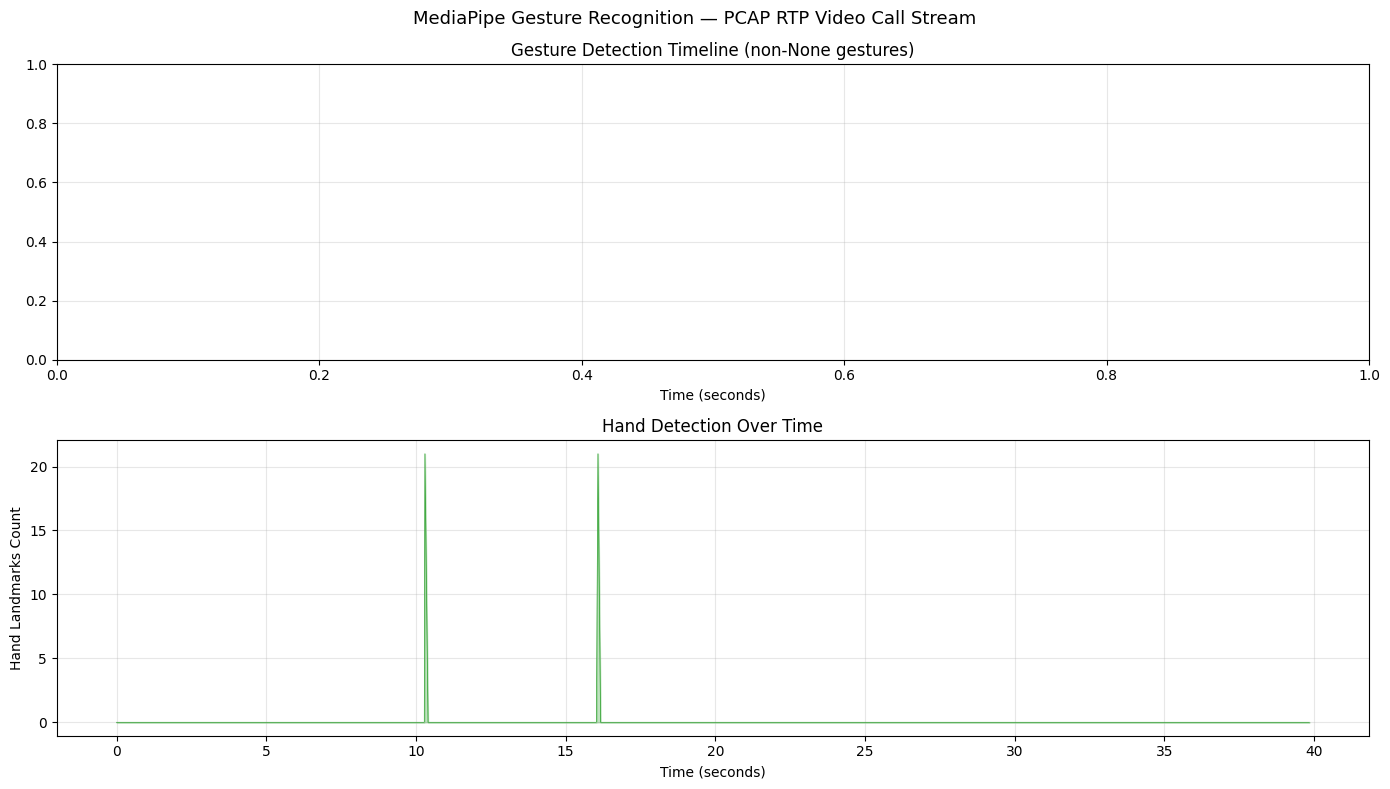

In [9]:
import matplotlib.pyplot as plt
import numpy as np

print('=== Gesture Recognition Summary ===')
print(f'Total frames analyzed: {len(gesture_results)}')
print(f'\nGesture counts:')
for gesture, count in sorted(gesture_counts.items(), key=lambda x: -x[1]):
    pct = 100 * count / max(len(gesture_results), 1)
    bar = '█' * int(pct / 2)
    print(f'  {gesture:15s}: {count:4d} ({pct:5.1f}%) {bar}')

# Hands detected over time
hands_detected = [r for r in gesture_results if r.hand_landmarks_count > 0]
meaningful_gestures = [r for r in gesture_results 
                       if r.gestures and any(g[0] != 'None' for g in r.gestures)]

print(f'\nHands detected in: {len(hands_detected)}/{len(gesture_results)} frames '
      f'({100*len(hands_detected)/max(len(gesture_results),1):.1f}%)')
print(f'Meaningful gestures (non-None): {len(meaningful_gestures)} frames')

# ─── Visualization ───
if gesture_results:
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    # Plot 1: Gesture timeline
    ax1 = axes[0]
    times = [r.timestamp_ms / 1000 for r in gesture_results]
    gesture_names = sorted(set(g[0] for r in gesture_results for g in r.gestures)) if meaningful_gestures else []
    
    for r in gesture_results:
        for g_name, g_score in r.gestures:
            if g_name != 'None' and g_name in gesture_names:
                idx = gesture_names.index(g_name)
                ax1.scatter(r.timestamp_ms / 1000, idx, c='tab:blue', s=20, alpha=0.6)
    
    if gesture_names:
        ax1.set_yticks(range(len(gesture_names)))
        ax1.set_yticklabels(gesture_names)
    ax1.set_xlabel('Time (seconds)')
    ax1.set_title('Gesture Detection Timeline (non-None gestures)')
    ax1.grid(True, alpha=0.3)

    # Plot 2: Hand landmarks count over time
    ax2 = axes[1]
    lm_times = [r.timestamp_ms / 1000 for r in gesture_results]
    lm_counts = [r.hand_landmarks_count for r in gesture_results]
    ax2.fill_between(lm_times, lm_counts, alpha=0.3, color='tab:green')
    ax2.plot(lm_times, lm_counts, color='tab:green', linewidth=0.5)
    ax2.set_xlabel('Time (seconds)')
    ax2.set_ylabel('Hand Landmarks Count')
    ax2.set_title('Hand Detection Over Time')
    ax2.grid(True, alpha=0.3)

    plt.suptitle('MediaPipe Gesture Recognition — PCAP RTP Video Call Stream', fontsize=13)
    plt.tight_layout()
    plt.show()

    # Gesture distribution pie chart
    if gesture_counts:
        fig2, ax3 = plt.subplots(figsize=(8, 6))
        labels = list(gesture_counts.keys())
        values = list(gesture_counts.values())
        colors = plt.cm.Set3(np.linspace(0, 1, len(labels)))
        ax3.pie(values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
        ax3.set_title('Gesture Distribution')
        plt.tight_layout()
        plt.show()

## 8. Test với video MP4 (video_call_sample.mp4)

So sánh kết quả gesture recognition trên file MP4 trực tiếp vs pcap RTP stream.
Điều này giúp xác nhận pipeline pcap hoạt động đúng.

In [10]:
import cv2
import os
import time
from collections import defaultdict

MP4_PATH = 'video/baby_hand_clap.mp4'

# ─── Option lưu output ───
SAVE_OUTPUT_MP4 = True  
os.makedirs('runs', exist_ok=True)

# ─── Reset for MP4 test ───
mp4_results: list[GestureResult] = []
mp4_gesture_counts = defaultdict(int)

# Realtime visualization state for MP4
mp4_latest_hand_results_for_overlay = []
mp4_latest_dynamic_gesture = None

# ─── Metrics tracking ───
mp4_frame_start_times = {}
mp4_latencies = []
mp4_latest_latency = 0.0

mp4_dynamic_recognizer = DynamicGestureRecognizer(window_size=20, wave_threshold=3)
mp4_dynamic_processing_times = []  # To track efficiency of dynamic heuristic

def mp4_result_callback(
    result: mp_vision.GestureRecognizerResult,
    output_image: mp.Image,
    timestamp_ms: int,
):
    global mp4_latest_hand_results_for_overlay, mp4_latest_latency, mp4_latest_dynamic_gesture
    cb_time = time.monotonic()
    
    # Calculate inference latency
    start_t = mp4_frame_start_times.get(timestamp_ms)
    if start_t is not None:
        latency_ms = (cb_time - start_t) * 1000
        mp4_latencies.append(latency_ms)
        mp4_latest_latency = latency_ms

    # Update Dynamic Gesture Recognizer
    start_dynamic_time = time.perf_counter()
    detected_dynamic = mp4_dynamic_recognizer.update(result.hand_landmarks, timestamp_ms)
    dynamic_processing_time = (time.perf_counter() - start_dynamic_time) * 1000
    mp4_dynamic_processing_times.append(dynamic_processing_time)
    
    if detected_dynamic:
        mp4_latest_dynamic_gesture = detected_dynamic
    else:
        mp4_latest_dynamic_gesture = None

    hand_results = []
    gestures = []
    handedness_list = []
    landmarks_count = 0

    if result.hand_landmarks:
        landmarks_count = sum(len(lm) for lm in result.hand_landmarks)

    if result.handedness:
        for hand in result.handedness:
            for h in hand:
                handedness_list.append((h.category_name, h.score))

    if result.hand_landmarks and result.gestures:
        for hand_landmarks, hand_gestures in zip(result.hand_landmarks, result.gestures):
            best_gesture = hand_gestures[0] if hand_gestures else None
            
            # Ghi đè Static Gesture bằng Dynamic Gesture
            if mp4_latest_dynamic_gesture:
                g_name = mp4_latest_dynamic_gesture
                g_score = 1.0
            elif best_gesture:
                g_name = best_gesture.category_name
                g_score = best_gesture.score
            else:
                g_name = 'None'
                g_score = 0.0
                
            if g_name != 'None':
                gestures.append((g_name, g_score))
                mp4_gesture_counts[g_name] += 1
                hand_results.append({
                    'gesture': g_name,
                    'score': g_score,
                    'landmarks': hand_landmarks
                })

    mp4_latest_hand_results_for_overlay = hand_results

    mp4_results.append(GestureResult(
        timestamp_ms=timestamp_ms,
        gestures=gestures,
        handedness=handedness_list,
        hand_landmarks_count=landmarks_count,
        processing_time_ms=mp4_latest_latency
    ))


# Cấu hình với thiết bị đã chọn
mp4_device = DEVICE
try:
    mp4_base_options = get_base_options(MODEL_PATH, device=mp4_device)
    mp4_options = GestureRecognizerOptions(
        base_options=mp4_base_options,
        running_mode=VisionRunningMode.LIVE_STREAM,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5,
        result_callback=mp4_result_callback,
    )
except Exception:
    mp4_base_options = get_base_options(MODEL_PATH, device='CPU')
    mp4_options = GestureRecognizerOptions(
        base_options=mp4_base_options,
        running_mode=VisionRunningMode.LIVE_STREAM,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5,
        result_callback=mp4_result_callback,
    )

cap = cv2.VideoCapture(MP4_PATH)
if not cap.isOpened():
    print(f'Cannot open {MP4_PATH}')
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f'MP4: {width}x{height} @ {fps:.1f} fps, {total_frames} frames')
    print(f'Running LIVE_STREAM gesture recognition on MP4 ({mp4_device})...')

    out_video_mp4 = None
    if SAVE_OUTPUT_MP4:
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        out_video_mp4 = cv2.VideoWriter('runs/output_mp4_clap.mp4', fourcc, fps, (width, height))

    start_time = time.monotonic()
    frame_idx = 0

    with GestureRecognizer.create_from_options(mp4_options) as recognizer:
        while True:
            ret, frame = cap.read()
            if not ret:
                break

            rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)
            timestamp_ms = int(frame_idx * 1000 / fps)

            elapsed = time.monotonic() - start_time
            target = frame_idx / fps
            if target > elapsed:
                time.sleep(target - elapsed)

            mp4_frame_start_times[timestamp_ms] = time.monotonic()
            try:
                recognizer.recognize_async(mp_image, timestamp_ms)
            except Exception as e:
                pass 

            info_text = f'{frame_idx}/{total_frames} | Lat: {mp4_latest_latency:.1f}ms'
            annotated_mp4 = draw_gesture_overlay(rgb_frame, mp4_latest_hand_results_for_overlay, info_text)
            
            if out_video_mp4 is not None:
                out_video_mp4.write(cv2.cvtColor(annotated_mp4, cv2.COLOR_RGB2BGR))

            frame_idx += 1
            if frame_idx % 100 == 0:
                print(f'  ... {frame_idx}/{total_frames} frames')

        time.sleep(0.5)

    if out_video_mp4 is not None:
        out_video_mp4.release()

    cap.release()
    total_time = time.monotonic() - start_time

    print(f'{"═" * 60}')
    print(f'MP4 LIVE_STREAM complete: {frame_idx} frames in {total_time:.1f}s')
    
    # ─── HIỂN THỊ METRICS ───
    print(f'ĐÁNH GIÁ METRICS - DYNAMIC GESTURE (RULE-BASED)')
    if mp4_latencies:
        avg_latency = sum(mp4_latencies) / len(mp4_latencies)
        print(f'  - Tổng độ trễ Inference (End-to-end): {avg_latency:.2f} ms/frame')
    if mp4_dynamic_processing_times:
        avg_dyn_time = sum(mp4_dynamic_processing_times) / len(mp4_dynamic_processing_times)
        print(f'  - Thời gian chạy thuật toán Rule-based: {avg_dyn_time:.4f} ms/frame')
        
    print(f'- Tổng số frames nhận diện: {len(mp4_results)}')
    
    wave_count = mp4_gesture_counts.get("Wave", 0)
    clap_count = mp4_gesture_counts.get("Clap", 0)
    print(f'  - Số frame được gán nhãn Wave: {wave_count}')
    print(f'  - Số frame được gán nhãn Clap: {clap_count}')
    
    # Giả định MP4_PATH là wave_hand.mp4, thì Clap là False Positive
    if "wave" in MP4_PATH.lower():
        accuracy_heuristic = 100.0 * wave_count / (wave_count + clap_count) if (wave_count + clap_count) > 0 else 0
        print(f'  - Ground Truth = Wave. False Positives (Clap) = {clap_count}')
        print(f'  -> Độ chính xác phân loại động: {accuracy_heuristic:.1f}%')



💻 Đã cấu hình Delegate: CPU (XNNPACK)
MP4: 720x1280 @ 30.0 fps, 276 frames
Running LIVE_STREAM gesture recognition on MP4 (CPU)...


I0000 00:00:1791432898.551564    9779 hand_gesture_recognizer_graph.cc:257] Custom gesture classifier is not defined.
W0000 00:00:1791432898.567132    9782 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791432898.584360    9782 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791432898.585026    9783 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791432898.585088    9783 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  ... 100/276 frames
  ... 200/276 frames
════════════════════════════════════════════════════════════
MP4 LIVE_STREAM complete: 276 frames in 9.8s
ĐÁNH GIÁ METRICS - DYNAMIC GESTURE (RULE-BASED)
  - Tổng độ trễ Inference (End-to-end): 32.20 ms/frame
  - Thời gian chạy thuật toán Rule-based: 0.0632 ms/frame
- Tổng số frames nhận diện: 271
  - Số frame được gán nhãn Wave: 166
  - Số frame được gán nhãn Clap: 24


## 9. Template tích hợp Video Call Real-time

Code mẫu cho việc tích hợp vào hệ thống video call thực tế,
nhận RTP packets từ UDP socket (tương thích với `mock-video-rtp-sender`).

In [11]:
# ═══════════════════════════════════════════════════════════════
# TEMPLATE & CHẠY THỬ: Real-time Video Call Gesture Recognition (UDP)
# ═══════════════════════════════════════════════════════════════
import socket
import struct
import time
import threading
import av
import numpy as np
import mediapipe as mp
import pcap_parser

UDP_PORT = 41000


class RealTimeGestureRecognizer:
    """
    Nhận stream video RTP H264 qua UDP socket thời gian thực,
    tương thích trực tiếp với mock-video-rtp-sender và WebRTC gateway.
    """
    def __init__(self, udp_port: int = UDP_PORT, model_path: str = MODEL_PATH, device: str = 'CPU'):
        self.udp_port = udp_port
        self.model_path = model_path
        self.device = device
        self.running = False
        self.frames_decoded = 0
        self.gesture_log = []

        # H264 Decoder
        self.codec = av.CodecContext.create('h264', 'r')
        self.codec.open()

        # NALU Reassembly state
        self.fu_a_buffer = bytearray()
        self.current_au_nalus = []
        self.current_rtp_ts = None

    def _on_gesture_result(self, result, output_image, timestamp_ms):
        if result.gestures:
            for hand_gestures in result.gestures:
                for gesture in hand_gestures:
                    if gesture.category_name != 'None':
                        self.gesture_log.append((timestamp_ms, gesture.category_name, gesture.score))
                        print(f'  [REALTIME UDP 🤚] t={timestamp_ms}ms: {gesture.category_name} ({gesture.score:.2f})')

    def run(self, duration: float = 10.0):
        """Lắng nghe RTP packet qua UDP và chạy nhận diện cử chỉ."""
        delegate = mp.tasks.BaseOptions.Delegate.GPU if self.device.upper() == 'GPU' else mp.tasks.BaseOptions.Delegate.CPU
        options = mp.tasks.vision.GestureRecognizerOptions(
            base_options=mp.tasks.BaseOptions(model_asset_path=self.model_path, delegate=delegate),
            running_mode=mp.tasks.vision.RunningMode.LIVE_STREAM,
            num_hands=2,
            result_callback=self._on_gesture_result,
        )

        sock = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
        sock.bind(('0.0.0.0', self.udp_port))
        sock.settimeout(1.5)
        self.running = True
        print(f'Đang lắng nghe RTP trên UDP port {self.udp_port} ({self.device})...')

        with mp.tasks.vision.GestureRecognizer.create_from_options(options) as recognizer:
            start_time = time.monotonic()
            base_time = None
            prev_ts_ms = -1

            while self.running and (time.monotonic() - start_time) < duration:
                try:
                    data, _ = sock.recvfrom(65535)
                except socket.timeout:
                    continue

                pkt = pcap_parser.parse_rtp_from_raw(data, time.monotonic() - start_time)
                if not pkt:
                    continue

                if base_time is None:
                    base_time = pkt.timestamp

                # Xử lý NALU reassembly & decode khi hoàn thành Access Unit
                if self.current_rtp_ts is not None and pkt.timestamp != self.current_rtp_ts:
                    self._flush_au(recognizer, base_time, prev_ts_ms)

                self.current_rtp_ts = pkt.timestamp
                payload = pkt.payload
                nal_type = payload[0] & 0x1f

                if 1 <= nal_type <= 23:
                    self.current_au_nalus.append(bytes(payload))
                elif nal_type == 24:  # STAP-A
                    idx = 1
                    while idx + 2 <= len(payload):
                        size = struct.unpack('>H', payload[idx:idx+2])[0]
                        idx += 2
                        if size == 0 or idx + size > len(payload): break
                        self.current_au_nalus.append(bytes(payload[idx:idx+size]))
                        idx += size
                elif nal_type == 28:  # FU-A
                    fu_header = payload[1]
                    if (fu_header >> 7) & 1:
                        self.fu_a_buffer = bytearray([(payload[0] & 0xe0) | (fu_header & 0x1f)])
                    self.fu_a_buffer.extend(payload[2:])
                    if (fu_header >> 6) & 1:
                        self.current_au_nalus.append(bytes(self.fu_a_buffer))
                        self.fu_a_buffer.clear()

                if pkt.marker:
                    prev_ts_ms = self._flush_au(recognizer, base_time, prev_ts_ms)

            time.sleep(0.5)

        sock.close()
        print(f'Kết thúc. Đã giải mã {self.frames_decoded} frames, phát hiện {len(self.gesture_log)} cử chỉ.')

    def _flush_au(self, recognizer, base_time, prev_ts_ms):
        if not self.current_au_nalus:
            return prev_ts_ms
        annex_b = b''.join(b'\x00\x00\x00\x01' + n for n in self.current_au_nalus)
        self.current_au_nalus.clear()
        try:
            for pkt_av in self.codec.parse(annex_b):
                for frame in self.codec.decode(pkt_av):
                    rgb = frame.to_ndarray(format='rgb24')
                    self.frames_decoded += 1
                    ts_ms = int((self.current_rtp_ts - base_time) / 90)
                    if ts_ms <= prev_ts_ms:
                        ts_ms = prev_ts_ms + 1
                    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
                    recognizer.recognize_async(mp_img, ts_ms)
                    prev_ts_ms = ts_ms
        except Exception:
            pass
        return prev_ts_ms


# ─── 4. Chạy thử nghiệm UDP Real-time với Mock Sender ───
# Bỏ comment dòng dưới để chạy receiver lắng nghe stream từ mock_sender.py:
# receiver = RealTimeGestureRecognizer(udp_port=41000, device=DEVICE)
# receiver.run(duration=10.0)

print('RealTimeGestureRecognizer đã sẵn sàng!')
print('\nCách test 2 cửa sổ/terminal:')
print('  • Terminal 1 (Chạy sender):  python mock_sender.py --input video/input_video.txt --target 127.0.0.1:41000')
print('  • Terminal 2 hoặc Cell này:  chạy receiver.run(duration=15.0)')


RealTimeGestureRecognizer đã sẵn sàng!

Cách test 2 cửa sổ/terminal:
  • Terminal 1 (Chạy sender):  python mock_sender.py --input video/input_video.txt --target 127.0.0.1:41000
  • Terminal 2 hoặc Cell này:  chạy receiver.run(duration=15.0)
